# Day 2: Supervised learning on housing affordability

**Group 8** · IAAC MaAI 2026–27 · AI Methods · Day 2

**Goal:** predict next year's housing affordability (`affordability_next`) for 26 countries, using what is known this year.

**Data:** `data/housing_affordability_model_ready.csv` from Day 1 (one row = one country in one year, 1977–2024).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score, KFold, TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
SEED = 42

# works from the repo root or from notebook/
ROOT = Path(".") if (Path("data") / "housing_affordability_model_ready.csv").exists() else Path("..")
FIG_DIR, MODEL_DIR = ROOT / "figures", ROOT / "models"
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data" / "housing_affordability_model_ready.csv")
df = df.sort_values(["year", "iso"]).reset_index(drop=True)   # time order, needed for the split
print(df.shape)
df.head()

(1210, 29)


,affordability_next,iso,year,decade,affordability,real_house_price_index,real_personal_disposable_income,real_hpi_change_pct,real_income_change_pct,affordability_lag1,...,region_Africa,region_Asia,region_Central/Eastern Europe,region_Latin America,region_Middle East,region_Nordic,region_North America,region_Oceania,region_Southern Europe,region_Western Europe
0,38.061170,AUS,1977,1970,39.048834,21.43,54.88,-1.016166,-0.290698,39.335029,...,0,0,0,0,0,0,0,1,0,0
1,80.660995,BEL,1977,1970,75.379990,45.13,59.87,11.157635,-1.334871,66.908372,...,0,0,0,0,0,0,0,0,0,1
2,49.394222,CAN,1977,1970,49.952553,26.32,52.69,-5.831843,-0.396975,52.835539,...,0,0,0,0,0,0,1,0,0,0
3,97.436798,CHE,1977,1970,96.674498,53.49,55.33,-0.539234,1.244282,98.408051,...,0,0,0,0,0,0,0,0,0,1
4,249.769748,COL,1977,1970,274.798387,149.93,54.56,-11.623932,3.411676,321.550417,...,0,0,0,1,0,0,0,0,0,0


# 1. Core concepts

## 1.1 Train / test split

The model learns from the **training set**; the **test set** is kept aside and used once at the end.

Our rows are years, so we split **by time** instead of at random: neighbouring years of a country are almost identical, so a random split would let the model "see the future".
- **Train:** 1977–2014 · **Test:** 2015–2024

**Target:** `affordability_next` is very skewed, so we predict its **log10**.

**Inputs removed:** the target, `iso` (an identifier), and `data_reliable` / `is_latest_year` (constant in this file). We also turn the region columns back into one text column `region` and `decade` into text, to encode them ourselves in section 2.

In [2]:
region_cols = [c for c in df.columns if c.startswith("region_")]

X = df.drop(columns=["affordability_next", "iso", "data_reliable", "is_latest_year"] + region_cols)
X["log_affordability"] = np.log10(df["affordability"])
X["region"] = df[region_cols].idxmax(axis=1).str.replace("region_", "")
X["decade"] = df["decade"].astype(str) + "s"
y = np.log10(df["affordability_next"])

is_train = df["year"] < 2015
X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]
print("train:", X_train.shape, " test:", X_test.shape)

train: (950, 17)  test: (260, 17)


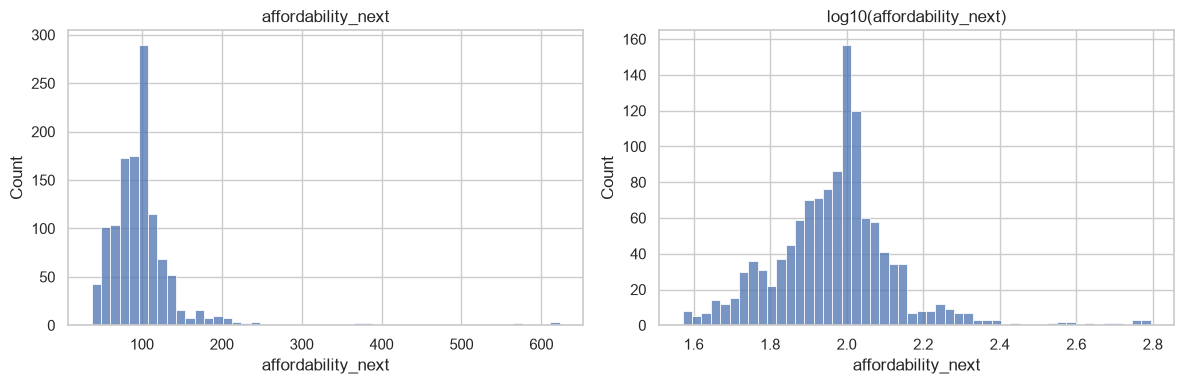

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["affordability_next"], bins=50, ax=axes[0]).set_title("affordability_next")
sns.histplot(y, bins=50, ax=axes[1]).set_title("log10(affordability_next)")
plt.tight_layout()
plt.show()

## 1.2 Underfitting and overfitting

- **Underfitting:** model too simple → high error on train *and* test.
- **Overfitting:** model too complex → very low train error, high test error.

Small synthetic example: window-to-wall ratio vs energy demand (a U-shaped curve + noise), fitted with polynomials of degree 1, 2 and 15.

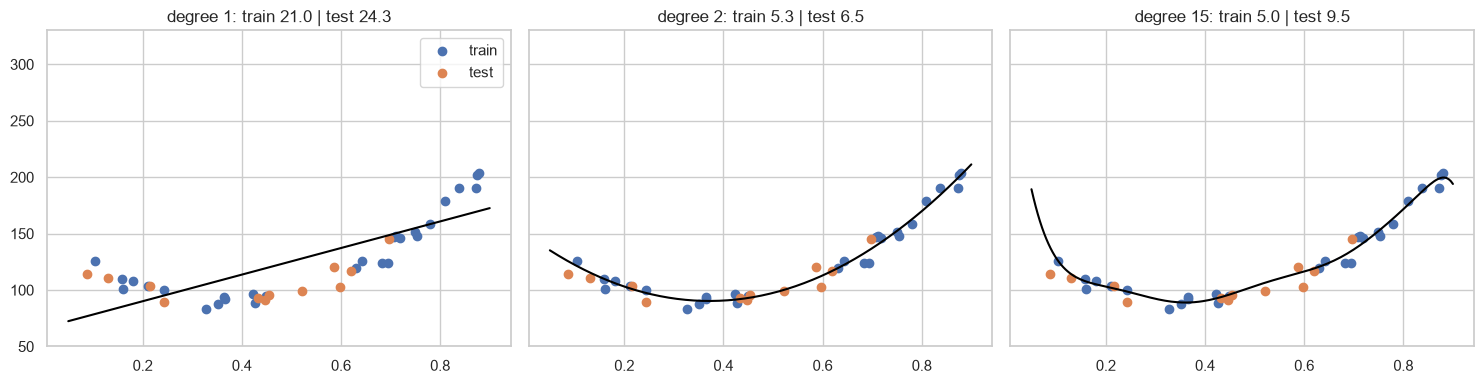

In [4]:
rng = np.random.default_rng(SEED)
wwr = rng.uniform(0.05, 0.9, 40)
demand = 90 + 400 * (wwr - 0.35) ** 2 + rng.normal(0, 8, 40)
w_train, w_test, d_train, d_test = train_test_split(wwr.reshape(-1, 1), demand, test_size=0.3, random_state=SEED)

grid = np.linspace(0.05, 0.9, 200).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, degree in zip(axes, [1, 2, 15]):
    poly = Pipeline([("poly", PolynomialFeatures(degree)), ("scale", StandardScaler()), ("lr", LinearRegression())])
    poly.fit(w_train, d_train)
    train_err = root_mean_squared_error(d_train, poly.predict(w_train))
    test_err = root_mean_squared_error(d_test, poly.predict(w_test))
    ax.scatter(w_train, d_train, label="train")
    ax.scatter(w_test, d_test, label="test")
    ax.plot(grid, poly.predict(grid), color="black")
    ax.set_ylim(50, 330)
    ax.set_title(f"degree {degree}: train {train_err:.1f} | test {test_err:.1f}")
axes[0].legend()
plt.tight_layout()
plt.show()

Degree 1 underfits (both errors high), degree 2 fits well, degree 15 has the lowest training error but a higher test error: it learned the noise.

## 1.3 Cross-validation

To compare models we can't use the test set, so we use **K-fold cross-validation** on the training set: split it into 5 folds, train on 4, validate on the 5th, repeat 5 times, and average.

Because our data is ordered in time we use `TimeSeriesSplit`: each fold trains on earlier years and validates on later years. A normal shuffled `KFold` is shown for comparison.

In [5]:
tscv = TimeSeriesSplit(n_splits=5)
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)

tree = DecisionTreeRegressor(max_depth=5, random_state=SEED)
X_num = X_train.drop(columns=["region", "decade"])   # trees can use the numbers directly

time_scores = -cross_val_score(tree, X_num, y_train, cv=tscv, scoring="neg_mean_absolute_error")
shuffled_scores = -cross_val_score(tree, X_num, y_train, cv=kfold, scoring="neg_mean_absolute_error")
print(f"Time-based CV MAE: {time_scores.mean():.4f} ± {time_scores.std():.4f}")
print(f"Shuffled CV MAE:   {shuffled_scores.mean():.4f} ± {shuffled_scores.std():.4f}")

Time-based CV MAE: 0.0260 ± 0.0062
Shuffled CV MAE:   0.0227 ± 0.0012


The shuffled folds look about 13% better (0.0227 vs 0.0260) because the model validates on years that sit between training years. Time-based CV gives the honest estimate, so we use `tscv` from now on.

## 1.4 Baselines

A model is only useful if it beats a simple guess:
- **Mean baseline:** always predict the average (`DummyRegressor`).
- **"Next year = this year":** for our data a much stronger baseline, since affordability changes slowly.

In [6]:
mean_scores = -cross_val_score(DummyRegressor(), X_num, y_train, cv=tscv, scoring="neg_mean_absolute_error")

# "next year = this year" needs no training: compare this year's value with next year's on the same folds
persistence_scores = [mean_absolute_error(y_train.iloc[val], X_train["log_affordability"].iloc[val])
                      for _, val in tscv.split(X_train)]

print(f"Mean baseline MAE:          {mean_scores.mean():.4f}")
print(f"Next year = this year MAE:  {np.mean(persistence_scores):.4f}")
print(f"Decision tree MAE:          {time_scores.mean():.4f}")

Mean baseline MAE:          0.1201
Next year = this year MAE:  0.0204
Decision tree MAE:          0.0260


The tree beats the mean baseline easily, but **not** "next year = this year" (0.0204). That simple rule is the real bar for every model below.

MAE is on the log10 scale: an error of 0.02 means about **±4.7%** (10^0.02 = 1.047).

## 1.5 Data leakage

**Leakage** = using information that is not available when making the prediction. Example: next year's growth is computed from the target, so `log10(next) = log10(this) + log10(growth)`.

In [7]:
X_leaky = X_num.assign(log_growth_next=np.log10(df.loc[is_train, "affordability_next"] / df.loc[is_train, "affordability"]))

honest = cross_val_score(LinearRegression(), X_num, y_train, cv=tscv, scoring="r2")
leaky = cross_val_score(LinearRegression(), X_leaky, y_train, cv=tscv, scoring="r2")
print(f"R² honest: {honest.mean():.3f}   R² with leak: {leaky.mean():.3f}")

R² honest: 0.973   R² with leak: 1.000


A perfect R² of 1.0 is a red flag: we cannot know next year's growth when forecasting. The same happens, more quietly, if we fit a scaler or imputer on all data before splitting. **Pipelines** prevent that.

# 2. Preprocessing pipeline

Each column type gets its own preprocessing:
- **Numeric:** fill missing values with the median → scale
- **`region`** (nominal, no order): fill missing values → **one-hot** encode
- **`decade`** (ordinal): **ordinal** encode with the order 1970s < … < 2020s

`country` is left out on purpose: with one column per country the model could just memorise each country's index level.

A `ColumnTransformer` applies each step to its columns; a `Pipeline` chains it with the model, so everything is fitted on training data only (also inside every CV fold).

In [8]:
numeric_cols = X.columns.drop(["region", "decade"]).tolist()
decade_order = ["1970s", "1980s", "1990s", "2000s", "2010s", "2020s"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
    ("region", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))]), ["region"]),
    ("decade", OrdinalEncoder(categories=[decade_order], handle_unknown="use_encoded_value", unknown_value=-1), ["decade"]),
])

pipe = Pipeline([("prep", preprocess), ("model", Ridge())])
pipe.fit(X_train, y_train)
print(len(numeric_cols) + 2, "input columns ->", len(pipe.named_steps["prep"].get_feature_names_out()), "after preprocessing")
pipe

17 input columns -> 26 after preprocessing


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['year','decade','affordability',...,'gfc_period','log_affordability', 'region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('region', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset o

Why not other encoders?
- **Ordinal / label encoding of `region`** would invent an order (e.g. "Western Europe = 9 > Asia = 1"), which misleads linear models.
- **Target encoding** is useful for hundreds of categories; with 10 regions, one-hot is simpler and safe.

# 3. Model comparison

All models use the same pipeline, the same time-based folds and the same metric (MAE on log10). Trees don't need scaling but it doesn't hurt them, so we keep one pipeline for simplicity.

In [9]:
models = {
    "Mean baseline": DummyRegressor(),
    "Linear regression": LinearRegression(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=10),
    "Decision tree": DecisionTreeRegressor(max_depth=5, random_state=SEED),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=SEED),
}

results = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = -cross_val_score(pipe, X_train, y_train, cv=tscv, scoring="neg_mean_absolute_error")
    results.append({"model": name, "MAE mean": scores.mean(), "MAE std": scores.std()})
results.append({"model": "Next year = this year", "MAE mean": np.mean(persistence_scores),
                "MAE std": np.std(persistence_scores)})

results = pd.DataFrame(results).set_index("model").sort_values("MAE mean")
results["≈ error (%)"] = (10 ** results["MAE mean"] - 1) * 100
results.round(4)

,MAE mean,MAE std,≈ error (%)
model,,,
Ridge,0.0167,0.0031,3.9240
Linear regression,0.0171,0.0037,4.0230
Random forest,0.0204,0.0055,4.8081
Next year = this year,0.0204,0.0033,4.8195
Gradient boosting,0.0235,0.0080,5.5665
Decision tree,0.0279,0.0093,6.6390
KNN,0.0441,0.0049,10.6762
Mean baseline,0.1201,0.0361,31.8511


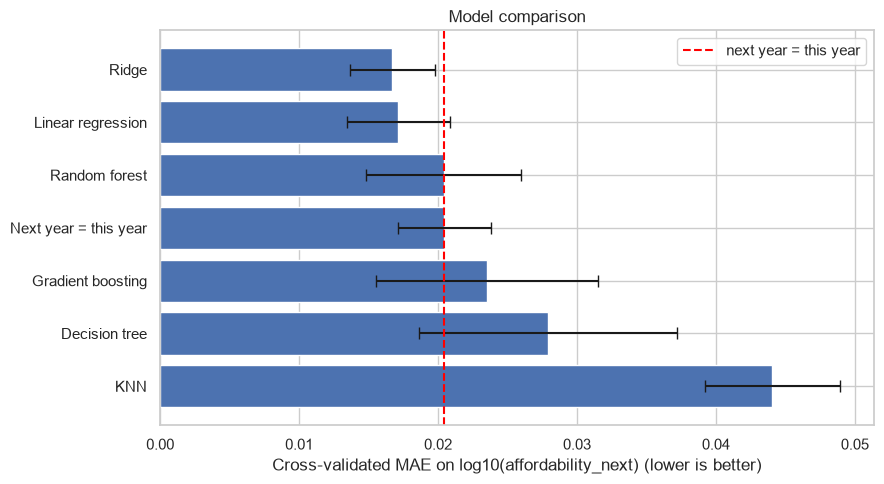

In [10]:
plot_data = results.drop("Mean baseline").sort_values("MAE mean", ascending=False)
plt.figure(figsize=(9, 5))
plt.barh(plot_data.index, plot_data["MAE mean"], xerr=plot_data["MAE std"], capsize=4)
plt.axvline(results.loc["Next year = this year", "MAE mean"], color="red", linestyle="--", label="next year = this year")
plt.xlabel("Cross-validated MAE on log10(affordability_next) (lower is better)")
plt.title("Model comparison")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "day2_01_model_comparison.png", dpi=150)
plt.show()

- **Ridge is best** (MAE 0.0167, ≈ 3.9% error) and is the only model clearly below "next year = this year" (≈ 4.8%).
- Random forest only ties with the persistence baseline; gradient boosting, the tree and KNN are worse. Tree models can only predict levels seen in training, but affordability keeps moving to new levels.
- Differences smaller than the std (≈ 0.003–0.008) are not meaningful.

# 4. Diagnosis and tuning

## 4.1 Validation curve: decision tree depth

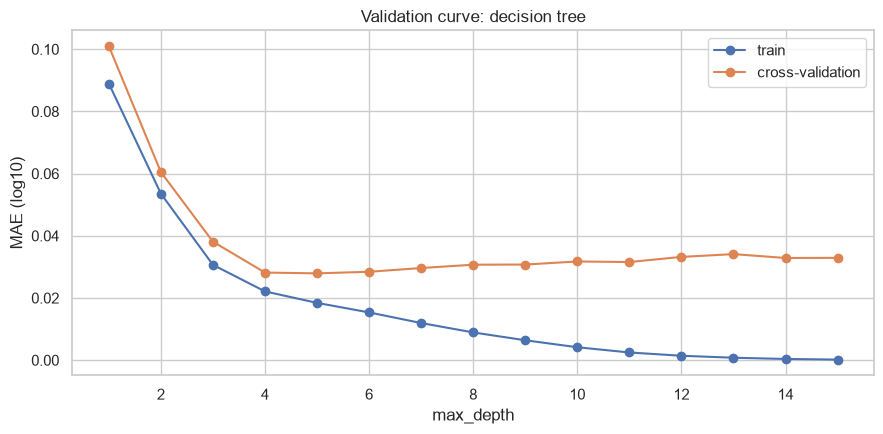

In [11]:
depths = range(1, 16)
train_mae, cv_mae = [], []
for d in depths:
    pipe = Pipeline([("prep", preprocess), ("model", DecisionTreeRegressor(max_depth=d, random_state=SEED))])
    cv_mae.append(-cross_val_score(pipe, X_train, y_train, cv=tscv, scoring="neg_mean_absolute_error").mean())
    pipe.fit(X_train, y_train)
    train_mae.append(mean_absolute_error(y_train, pipe.predict(X_train)))

plt.figure(figsize=(9, 4.5))
plt.plot(depths, train_mae, "o-", label="train")
plt.plot(depths, cv_mae, "o-", label="cross-validation")
plt.xlabel("max_depth")
plt.ylabel("MAE (log10)")
plt.title("Validation curve: decision tree")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "day2_02_validation_curve.png", dpi=150)
plt.show()

Shallow trees (depth 1–3) underfit. From depth ≈ 5 the training error keeps falling towards 0 while the CV error stays flat and slowly rises: **overfitting**. Even the best tree (≈ 0.028) does not beat the persistence baseline.

## 4.2 Grid search: Ridge `alpha`

In [12]:
ridge_pipe = Pipeline([("prep", preprocess), ("model", Ridge())])
grid_search = GridSearchCV(ridge_pipe, {"model__alpha": [0.01, 0.1, 1, 10, 100]},
                           cv=tscv, scoring="neg_mean_absolute_error")
grid_search.fit(X_train, y_train)

print("Best alpha:", grid_search.best_params_)
print(f"Best CV MAE: {-grid_search.best_score_:.4f}")
pd.DataFrame({"alpha": grid_search.cv_results_["param_model__alpha"],
              "CV MAE": -grid_search.cv_results_["mean_test_score"]}).round(4)

Best alpha: {'model__alpha': 1}
Best CV MAE: 0.0167


,alpha,CV MAE
0,0.01,0.0171
1,0.10,0.0170
2,1.00,0.0167
3,10.00,0.0201
4,100.00,0.0288


`alpha` between 0.01 and 1 gives almost the same score; strong penalties (10, 100) hurt. The best is `alpha=1`, the default, so tuning brings no real gain. **Final model: Ridge (alpha=1).**

# 5. Final evaluation on the test set (once)

In [13]:
final_model = grid_search.best_estimator_   # refit on the whole training set
y_pred = final_model.predict(X_test)

actual, predicted = 10 ** y_test, 10 ** y_pred
persistence = 10 ** X_test["log_affordability"]

print(f"R² (log scale): {r2_score(y_test, y_pred):.3f}")
print(f"MAE:  {mean_absolute_error(actual, predicted):.2f} index points  (next year = this year: {mean_absolute_error(actual, persistence):.2f})")
print(f"RMSE: {root_mean_squared_error(actual, predicted):.2f} index points  (next year = this year: {root_mean_squared_error(actual, persistence):.2f})")
pct_error = (predicted - actual) / actual * 100
print(f"Within ±5%: {(pct_error.abs() <= 5).mean():.0%} of test country-years")

R² (log scale): 0.826
MAE:  3.28 index points  (next year = this year: 3.74)
RMSE: 4.75 index points  (next year = this year: 5.26)
Within ±5%: 83% of test country-years


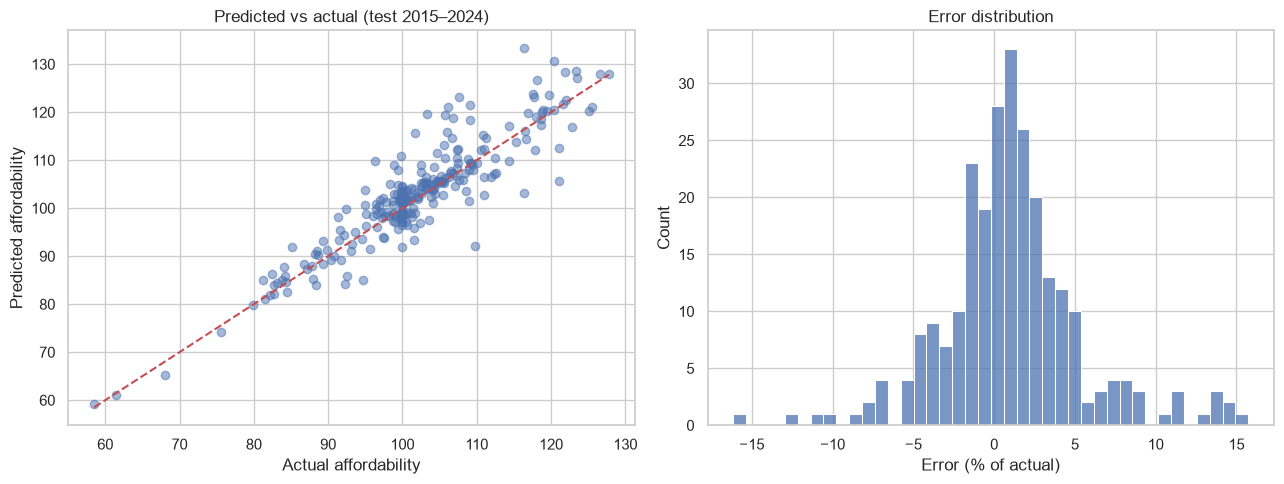

iso
ESP    0.8
BEL    0.9
FRA    1.0
JPN    4.1
SWE    4.1
CAN    4.8
Name: affordability_next, dtype: float64

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(actual, predicted, alpha=0.5)
axes[0].plot([actual.min(), actual.max()], [actual.min(), actual.max()], "r--")
axes[0].set_xlabel("Actual affordability")
axes[0].set_ylabel("Predicted affordability")
axes[0].set_title("Predicted vs actual (test 2015–2024)")
sns.histplot(pct_error, bins=40, ax=axes[1])
axes[1].set_xlabel("Error (% of actual)")
axes[1].set_title("Error distribution")
plt.tight_layout()
plt.savefig(FIG_DIR / "day2_03_test_results.png", dpi=150)
plt.show()

# errors per country
pct_error.abs().groupby(df.loc[~is_train, "iso"]).median().sort_values().round(1).iloc[[0, 1, 2, -3, -2, -1]]

- On 2015–2024 the model's MAE is **3.3 index points** vs 3.7 for "next year = this year" (≈ 12% smaller), R² 0.83, and **83%** of predictions are within ±5%.
- The test error is lower than the CV error because 2015–2024 was calmer than the folds with the 1980s–90s and 2008.
- Easiest: Spain, Belgium, France (≈ 1% error). Hardest: Japan, Sweden, Canada (≈ 4–5%), countries with sharp turns that our data cannot explain (no interest rates).

# 6. Interpretation

In [15]:
coefs = pd.Series(final_model.named_steps["model"].coef_,
                  index=final_model.named_steps["prep"].get_feature_names_out())
coefs[coefs.index.str.startswith("num__")].sort_values().round(4)

num__affordability_lag1                -0.0133
num__real_house_price_index            -0.0042
num__real_income_change_pct            -0.0039
num__price_shock_up                    -0.0019
num__gfc_period                        -0.0014
num__nominal_zero                       0.0000
num__price_shock_down                   0.0000
num__hyperinflation_country             0.0006
num__affordability_3yr_avg              0.0023
num__year                               0.0040
num__real_personal_disposable_income    0.0078
num__affordability                      0.0079
num__affordability_lag2                 0.0118
num__real_hpi_change_pct                0.0161
num__log_affordability                  0.1698
dtype: float64

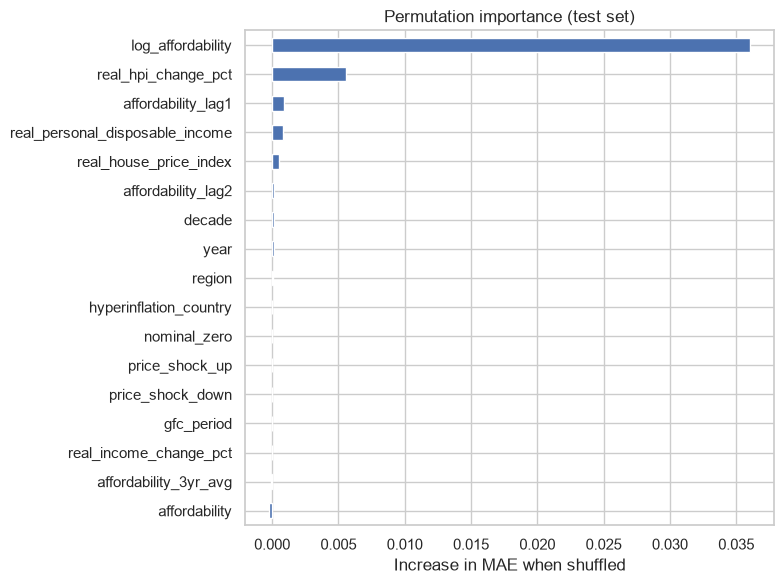

In [16]:
imp = permutation_importance(final_model, X_test, y_test, scoring="neg_mean_absolute_error",
                             n_repeats=10, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

importance.plot.barh(figsize=(8, 6), title="Permutation importance (test set)")
plt.xlabel("Increase in MAE when shuffled")
plt.tight_layout()
plt.savefig(FIG_DIR / "day2_04_feature_importance.png", dpi=150)
plt.show()

- **This year's affordability** (`log_affordability`) dominates: next year is mostly this year.
- **Real house price growth** (`real_hpi_change_pct`) is the main correction: fast price growth tends to continue (momentum).
- Region, decade and the Day 1 flags add almost nothing.
- The affordability columns (level, log, lags, 3-year average) are strongly correlated, so their individual coefficients (e.g. the negative `affordability_lag1`) should not be read one by one.

# 7. Save and reuse the model

In [17]:
joblib.dump(final_model, MODEL_DIR / "model.joblib")
loaded = joblib.load(MODEL_DIR / "model.joblib")

# example: Spain with its 2024 indicators -> forecast for 2025
spain = X[(df["iso"] == "ESP") & (df["year"] == 2024)]
print(f"Spain 2024: {spain['affordability'].item():.1f} -> forecast 2025: {10 ** loaded.predict(spain)[0]:.1f}")

# what if real house prices had risen 10% more in 2024?
what_if = spain.copy()
what_if["real_house_price_index"] *= 1.1
what_if["affordability"] *= 1.1
what_if["log_affordability"] = np.log10(what_if["affordability"])
what_if["real_hpi_change_pct"] += 10
print(f"With 10% faster price growth: forecast 2025: {10 ** loaded.predict(what_if)[0]:.1f}")

Spain 2024: 100.0 -> forecast 2025: 101.5
With 10% faster price growth: forecast 2025: 116.9


The saved pipeline takes raw columns and returns log10 affordability. A 10% stronger price rise gives a ≈ 15% higher forecast: more than the shock itself, because the model adds momentum.

# 8. Classification: will affordability get worse next year?

Same inputs, new target: **"worse"** if next year's affordability is higher than this year's, otherwise **"better"**. The classes are roughly balanced, so we report accuracy together with the F1 per class.

In [18]:
y_class = np.where(df["affordability_next"] > df["affordability"], "worse", "better")
yc_train, yc_test = y_class[is_train], y_class[~is_train]
print(pd.Series(yc_train).value_counts(normalize=True).round(2))

classifiers = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=3000),
    "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
}
for name, clf in classifiers.items():
    scores = cross_val_score(Pipeline([("prep", preprocess), ("model", clf)]),
                             X_train, yc_train, cv=tscv, scoring="f1_macro")
    print(f"{name:<20} macro F1 {scores.mean():.3f} ± {scores.std():.3f}")

better    0.51
worse     0.49
Name: proportion, dtype: float64
Baseline             macro F1 0.334 ± 0.039
Logistic regression  macro F1 0.677 ± 0.047
Decision tree        macro F1 0.669 ± 0.067


Random forest        macro F1 0.704 ± 0.028


              precision    recall  f1-score   support

      better       0.71      0.52      0.60       113
       worse       0.69      0.84      0.76       147

    accuracy                           0.70       260
   macro avg       0.70      0.68      0.68       260
weighted avg       0.70      0.70      0.69       260



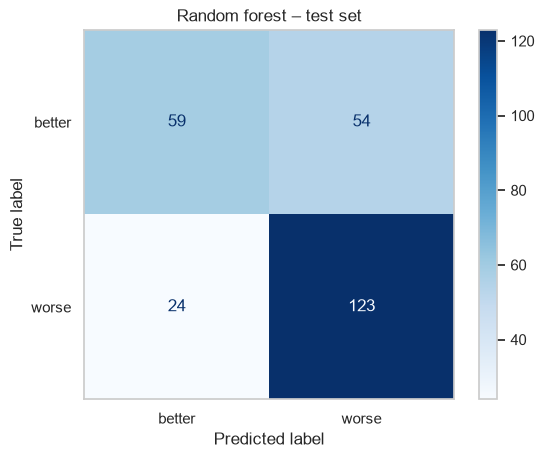

In [19]:
best_clf = Pipeline([("prep", preprocess), ("model", classifiers["Random forest"])]).fit(X_train, yc_train)
yc_pred = best_clf.predict(X_test)
print(classification_report(yc_test, yc_pred))

ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, cmap="Blues")
plt.title("Random forest – test set")
plt.grid(False)
plt.savefig(FIG_DIR / "day2_05_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

- Random forest has the best CV macro F1 (0.70 ± 0.03); the baseline only reaches 0.33.
- On the test years: accuracy 0.70, and **recall 0.84 for "worse"**: it finds most deteriorations, which matters most for an early warning.
- Its weak spot is "better" (recall 0.52): it often warns when affordability actually improves. A false alarm is the cheaper mistake here.

# 9. Conclusions

- **Split by time:** shuffled CV looked ≈ 13% better than it really is.
- **Leakage:** adding next year's growth gave a fake perfect R² of 1.0.
- **The real baseline is "next year = this year"** (≈ 4.8% error). Only the linear models clearly beat it.
- **Final model: Ridge** (CV MAE 0.0167, ≈ 3.9%; test MAE 3.3 index points, 83% within ±5%). Chosen because it is the most accurate, the fastest and easy to interpret.
- **Main drivers:** this year's affordability and real house price growth (momentum).
- **Classification:** a random forest predicts "worse next year" with macro F1 ≈ 0.70 and finds 84% of the test deteriorations.

**Limitations:** indexes, not money (levels are not comparable between countries); no interest rates, supply or migration data, so sharp turns (e.g. 2022) are missed; national averages only; 26 mostly high-income countries; one-year-ahead forecasts only.